# Product Line Profitability & Margin Performance Analysis

## Nassau Candy Distributor

### Project Overview

This project focuses on analysing the product-line profitability and margin performance of Nassau Candy Distributor.

The analysis uses sales, cost, gross profit and quantity data to evaluate the financial performance of individual products and business divisions.

### Problem Statement

The business needs to identify which products and divisions generate the highest profits, which products have low profit margins, and where cost-related inefficiencies may be affecting overall profitability.

### Project Objectives

- Analyse overall sales, costs and gross profit.
- Calculate product-level gross margins and profit per unit.
- Identify high-performing and underperforming products.
- Compare profitability across business divisions.
- Identify products contributing to 80% of revenue and profit.
- Analyse cost versus sales relationships.
- Evaluate monthly profitability trends and margin volatility.
- Develop actionable business recommendations.

### Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- Google Colab
- Streamlit

### Expected Outcomes

A detailed exploratory data analysis, product and division profitability insights, an interactive business dashboard and a final executive summary.

In [ ]:

# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All required libraries imported successfully!")


All required libraries imported successfully!


In [ ]:
# Loading the Nassau Candy dataset

df = pd.read_csv("/content/Nassau Candy Distributor.csv")

print("Dataset loaded successfully!")
print("-" * 40)
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])


Dataset loaded successfully!
----------------------------------------
Total Records: 10194
Total Columns: 18


### 4.1 Dataset Preview

The dataset is displayed to understand its structure and examine the first few records.

This preview helps identify the available attributes, understand the format of the data and check whether the dataset has been loaded correctly.

In [ ]:
# Display the first five records

df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


### 4.2 Dataset Dimensions

This section examines the size of the dataset by identifying the total number of records (rows) and attributes (columns).

Understanding the dataset dimensions helps determine the amount of information available for analysis.

In [ ]:
# Checking dataset dimensions

total_rows = df.shape[0]
total_columns = df.shape[1]

print("Dataset Dimensions")
print("-" * 30)
print("Total Number of Records:", total_rows)
print("Total Number of Features:", total_columns)


Dataset Dimensions
------------------------------
Total Number of Records: 10194
Total Number of Features: 18


### 4.3 Dataset Features

This section identifies all the attributes available in the dataset.

These features represent order information, customer details, product information, geographical details and financial metrics required for profitability analysis.

In [ ]:
# Displaying all column names

print("Total Number of Features:", len(df.columns))

print("\nAvailable Column Names:")
print("-" * 40)

for index, column in enumerate(df.columns, start=1):
    print(f"{index}. {column}")


Total Number of Features: 18

Available Column Names:
----------------------------------------
1. Row ID
2. Order ID
3. Order Date
4. Ship Date
5. Ship Mode
6. Customer ID
7. Country/Region
8. City
9. State/Province
10. Postal Code
11. Division
12. Region
13. Product ID
14. Product Name
15. Sales
16. Units
17. Gross Profit
18. Cost


### 4.4 Dataset Structure and Data Types

The structure of the dataset is examined using the Pandas `info()` function.

This function provides information about:
- Column names and their data types.
- Number of non-null values in each column.
- Total number of entries.
- Memory usage of the dataset.

This step helps identify missing values and determine whether data types need to be corrected before performing analysis.

In [ ]:
# Checking dataset structure and data types

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null 

### 4.5 Descriptive Statistical Analysis

Descriptive statistics are used to understand the distribution and characteristics of numerical variables in the dataset.

This analysis provides important statistical measures such as:
- Count: Number of available observations.
- Mean: Average value.
- Standard Deviation: Measures the variation in values.
- Minimum: Lowest observed value.
- Maximum: Highest observed value.
- Quartiles: Values that divide the observations into four equal parts.

These statistics help us understand the sales, cost, gross profit and quantity distributions before performing detailed profitability analysis.

In [ ]:
# Generating descriptive statistics

df.describe().T


,count,mean,std,min,25%,50%,75%,max
Row ID,10194.0,5097.500000,2942.898656,1.00,2549.25,5097.50,7645.75,10194.0
Customer ID,10194.0,134468.961154,20231.483007,100006.00,117212.00,133550.00,152051.00,192314.0
Sales,10194.0,13.908537,11.341020,1.25,7.20,10.80,18.00,260.0
Units,10194.0,3.791838,2.228317,1.00,2.00,3.00,5.00,14.0
Gross Profit,10194.0,9.166451,6.643740,0.25,4.90,7.47,12.25,130.0
Cost,10194.0,4.742087,5.061647,0.60,2.40,3.60,5.70,130.0


### 5.1 Missing Value Analysis

Missing value analysis is performed to identify incomplete records in the dataset.

Missing values can affect statistical calculations, visualizations and profitability metrics. Therefore, it is important to identify and handle them before proceeding with further analysis.

In [ ]:

# Checking missing values in each column

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

print("Missing Value Analysis")
print("-" * 40)

display(missing_summary)


Missing Value Analysis
----------------------------------------


,Missing Values,Missing Percentage
Row ID,0,0.0
Order ID,0,0.0
Order Date,0,0.0
Ship Date,0,0.0
Ship Mode,0,0.0
Customer ID,0,0.0
Country/Region,0,0.0
City,0,0.0
State/Province,0,0.0
Postal Code,0,0.0


### 5.2 Duplicate Record Analysis

Duplicate records are checked to identify whether the same complete record appears more than once in the dataset.

Duplicate entries may lead to overcounting of sales, units and gross profit. Identifying them helps maintain the accuracy and reliability of the analysis.

In [ ]:

# Checking duplicate records

duplicate_count = df.duplicated().sum()

print("Duplicate Record Analysis")
print("-" * 40)
print("Total Duplicate Records:", duplicate_count)

if duplicate_count == 0:
    print("Result: No duplicate records found.")
else:
    print("Result: Duplicate records are present.")


Duplicate Record Analysis
----------------------------------------
Total Duplicate Records: 0
Result: No duplicate records found.


### 5.3 Date Format Inspection

The Order Date and Ship Date columns are examined to understand their existing date formats.

Date conversion is necessary because date values stored as text cannot be reliably used for time-based calculations, monthly grouping and trend analysis.

In this step, we inspect sample date values before converting them into the appropriate datetime format.

In [ ]:

# Inspecting date columns

print("First 10 Order Dates:")
display(df["Order Date"].head(10))

print("\nFirst 10 Ship Dates:")
display(df["Ship Date"].head(10))

print("\nCurrent Data Types:")
print(df[["Order Date", "Ship Date"]].dtypes)


First 10 Order Dates:


,Order Date
0,03-01-2024
1,04-01-2024
2,04-01-2024
3,04-01-2024
4,05-01-2024
5,06-01-2024
6,06-01-2024
7,06-01-2024
8,06-01-2024
9,06-01-2024



First 10 Ship Dates:


,Ship Date
0,30-06-2026
1,01-07-2026
2,01-07-2026
3,01-07-2026
4,05-07-2026
5,03-07-2026
6,03-07-2026
7,30-06-2026
8,03-07-2026
9,03-07-2026



Current Data Types:
Order Date    object
Ship Date     object
dtype: object


### 5.4 Date Conversion

The Order Date and Ship Date columns are converted from text values into datetime format.

The dataset follows the DD-MM-YYYY date convention. Therefore, the appropriate date format is specified during conversion.

This conversion enables accurate date-based filtering, monthly aggregation and time-series profitability analysis.

In [ ]:

# Converting date columns into datetime format

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Date conversion completed successfully!")

print("\nUpdated Data Types:")
print(df[["Order Date", "Ship Date"]].dtypes)


Date conversion completed successfully!

Updated Data Types:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [ ]:

# Validating converted dates

print("Invalid Order Dates:", df["Order Date"].isna().sum())
print("Invalid Ship Dates:", df["Ship Date"].isna().sum())


Invalid Order Dates: 0
Invalid Ship Dates: 0


### 5.5 Financial Data Validation

Financial columns are examined to identify invalid or unusual values that may affect profitability calculations.

The following conditions are investigated:

- Zero or negative sales values.
- Negative cost values.
- Zero or negative unit quantities.
- Negative gross profit values.

This validation helps identify potential data quality issues before calculating financial performance indicators.

**Note:** Negative gross profit can be a legitimate business result when costs exceed sales. Therefore, it will be investigated rather than automatically removed.

In [ ]:

# Checking invalid and unusual financial values

print("FINANCIAL DATA VALIDATION")
print("=" * 45)

print("Zero or Negative Sales:",
      (df["Sales"] <= 0).sum())

print("Negative Cost:",
      (df["Cost"] < 0).sum())

print("Zero or Negative Units:",
      (df["Units"] <= 0).sum())

print("Negative Gross Profit:",
      (df["Gross Profit"] < 0).sum())


FINANCIAL DATA VALIDATION
Zero or Negative Sales: 0
Negative Cost: 0
Zero or Negative Units: 0
Negative Gross Profit: 0


### 5.6 Gross Profit Consistency Validation

The relationship between Sales, Cost and Gross Profit is examined to verify the financial consistency of the dataset.

According to the standard gross profit calculation:

**Gross Profit = Sales − Cost**

This validation helps identify discrepancies between the reported gross profit and the value calculated using sales and cost.

In [ ]:

# Validating gross profit calculations

df["Calculated Profit"] = df["Sales"] - df["Cost"]

profit_difference = (
    df["Gross Profit"] - df["Calculated Profit"]
).abs()

print("GROSS PROFIT CONSISTENCY CHECK")
print("=" * 45)

print("Maximum Difference:",
      round(profit_difference.max(), 2))

print("Mismatched Records:",
      (profit_difference > 0.01).sum())

if (profit_difference > 0.01).sum() == 0:
    print("Result: Gross profit values are consistent.")
else:
    print("Result: Some gross profit values need investigation.")


GROSS PROFIT CONSISTENCY CHECK
Maximum Difference: 0.0
Mismatched Records: 0
Result: Gross profit values are consistent.


### 5.7 Data Quality Assessment Summary

A final data quality assessment is performed to summarise the results of the cleaning and validation process.

The assessment covers missing values, duplicate records, invalid financial values and gross profit consistency.

This ensures that the dataset is sufficiently reliable for further exploratory data analysis and profitability calculations.

In [ ]:

# Final data quality assessment

quality_summary = pd.DataFrame({
    "Quality Check": [
        "Missing Values",
        "Duplicate Records",
        "Invalid Order Dates",
        "Invalid Ship Dates",
        "Zero or Negative Sales",
        "Negative Cost",
        "Zero or Negative Units",
        "Negative Gross Profit",
        "Gross Profit Mismatches"
    ],
    "Issue Count": [
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df["Order Date"].isna().sum(),
        df["Ship Date"].isna().sum(),
        (df["Sales"] <= 0).sum(),
        (df["Cost"] < 0).sum(),
        (df["Units"] <= 0).sum(),
        (df["Gross Profit"] < 0).sum(),
        (profit_difference > 0.01).sum()
    ]
})

display(quality_summary)


,Quality Check,Issue Count
0,Missing Values,0
1,Duplicate Records,0
2,Invalid Order Dates,0
3,Invalid Ship Dates,0
4,Zero or Negative Sales,0
5,Negative Cost,0
6,Zero or Negative Units,0
7,Negative Gross Profit,0
8,Gross Profit Mismatches,0


## 6. Feature Engineering

Feature engineering involves creating new analytical variables from the existing dataset.

In this project, additional profitability metrics are calculated to evaluate product performance, financial efficiency and contribution to overall business results.

### 6.1 Profitability KPI Calculation

The following key performance indicators (KPIs) are created:

- **Gross Margin (%):** Measures the percentage of sales retained as gross profit.
- **Profit per Unit:** Measures the gross profit earned per unit sold.
- **Revenue Contribution (%):** Measures the percentage of total revenue generated by a record.
- **Profit Contribution (%):** Measures the percentage of total gross profit generated by a record.

In [ ]:

# Calculating profitability KPIs

total_sales = df["Sales"].sum()
total_profit = df["Gross Profit"].sum()

# 1. Gross Margin Percentage
df["Gross Margin (%)"] = (
    df["Gross Profit"] / df["Sales"]
) * 100

# 2. Profit Per Unit
df["Profit per Unit"] = (
    df["Gross Profit"] / df["Units"]
)

# 3. Revenue Contribution Percentage
df["Revenue Contribution (%)"] = (
    df["Sales"] / total_sales
) * 100

# 4. Profit Contribution Percentage
df["Profit Contribution (%)"] = (
    df["Gross Profit"] / total_profit
) * 100

print("Profitability KPIs calculated successfully!")
print("Total Sales:", round(total_sales, 2))
print("Total Gross Profit:", round(total_profit, 2))


Profitability KPIs calculated successfully!
Total Sales: 141783.63
Total Gross Profit: 93442.8


### 6.2 Profitability KPI Preview and Validation

The newly created profitability metrics are examined to verify their calculations.

A sample of records is displayed along with the original financial attributes and newly calculated KPIs.

This step helps ensure that the derived metrics are available and correctly calculated before performing product-level and division-level analysis.

In [ ]:

# Displaying original financial data and calculated KPIs

kpi_columns = [
    "Product Name",
    "Sales",
    "Cost",
    "Gross Profit",
    "Units",
    "Gross Margin (%)",
    "Profit per Unit",
    "Revenue Contribution (%)",
    "Profit Contribution (%)"
]

display(df[kpi_columns].head(10))


,Product Name,Sales,Cost,Gross Profit,Units,Gross Margin (%),Profit per Unit,Revenue Contribution (%),Profit Contribution (%)
0,Wonka Bar - Milk Chocolate,6.50,2.28,4.22,2,64.923077,2.11,0.004584,0.004516
1,Wonka Bar - Triple Dazzle Caramel,7.50,2.60,4.90,2,65.333333,2.45,0.005290,0.005244
2,Wonka Bar - Nutty Crunch Surprise,10.47,3.00,7.47,3,71.346705,2.49,0.007384,0.007994
3,Wonka Bar -Scrumdiddlyumptious,10.80,3.30,7.50,3,69.444444,2.50,0.007617,0.008026
4,Wonka Bar - Triple Dazzle Caramel,11.25,3.90,7.35,3,65.333333,2.45,0.007935,0.007866
5,Wonka Bar -Scrumdiddlyumptious,32.40,9.90,22.50,9,69.444444,2.50,0.022852,0.024079
6,Wonka Bar - Triple Dazzle Caramel,7.50,2.60,4.90,2,65.333333,2.45,0.005290,0.005244
7,Wonka Bar - Milk Chocolate,9.75,3.42,6.33,3,64.923077,2.11,0.006877,0.006774
8,Wonka Bar - Nutty Crunch Surprise,6.98,2.00,4.98,2,71.346705,2.49,0.004923,0.005329
9,Wonka Bar - Milk Chocolate,13.00,4.56,8.44,4,64.923077,2.11,0.009169,0.009032


In [ ]:

# Validating the calculated KPI columns

calculated_kpis = [
    "Gross Margin (%)",
    "Profit per Unit",
    "Revenue Contribution (%)",
    "Profit Contribution (%)"
]

print("KPI Validation Results")
print("=" * 40)

for column in calculated_kpis:
    print(
        column,
        "→ Missing Values:",
        df[column].isna().sum()
    )


KPI Validation Results
Gross Margin (%) → Missing Values: 0
Profit per Unit → Missing Values: 0
Revenue Contribution (%) → Missing Values: 0
Profit Contribution (%) → Missing Values: 0


## 7. Overall Business Performance Analysis

This section evaluates the overall financial performance of Nassau Candy Distributor using key business metrics.

The analysis focuses on total revenue, total cost, gross profit, units sold and overall gross margin.

These metrics establish a baseline for understanding the company's financial performance before examining individual products and divisions.

### 7.1 Overall Business Performance KPIs

Key financial indicators are calculated using the complete dataset to understand the overall business performance.

The overall gross margin is calculated using total gross profit divided by total sales rather than averaging individual transaction margins.

In [ ]:

# Calculating overall business performance

total_revenue = df["Sales"].sum()
total_cost = df["Cost"].sum()
total_gross_profit = df["Gross Profit"].sum()
total_units_sold = df["Units"].sum()

overall_gross_margin = (
    total_gross_profit / total_revenue
) * 100

average_selling_price = (
    total_revenue / total_units_sold
)

average_profit_per_unit = (
    total_gross_profit / total_units_sold
)

# Creating a business performance summary

business_summary = pd.DataFrame({
    "Business KPI": [
        "Total Revenue",
        "Total Cost",
        "Total Gross Profit",
        "Total Units Sold",
        "Overall Gross Margin (%)",
        "Average Selling Price per Unit",
        "Average Profit per Unit"
    ],
    "Value": [
        total_revenue,
        total_cost,
        total_gross_profit,
        total_units_sold,
        overall_gross_margin,
        average_selling_price,
        average_profit_per_unit
    ]
})

display(
    business_summary.style.format({
        "Value": "{:,.2f}"
    })
)


,Business KPI,Value
0,Total Revenue,"141,783.63"
1,Total Cost,"48,340.83"
2,Total Gross Profit,"93,442.80"
3,Total Units Sold,"38,654.00"
4,Overall Gross Margin (%),65.91
5,Average Selling Price per Unit,3.67
6,Average Profit per Unit,2.42


### 7.2 Overall Financial Performance Visualization

A comparative bar chart is created to visualize the company's total revenue, total cost and gross profit.

This visualization provides a clear overview of the financial relationship between sales, expenditure and profitability.

It helps identify how much revenue is generated, how much is spent on product costs and how much gross profit is retained.

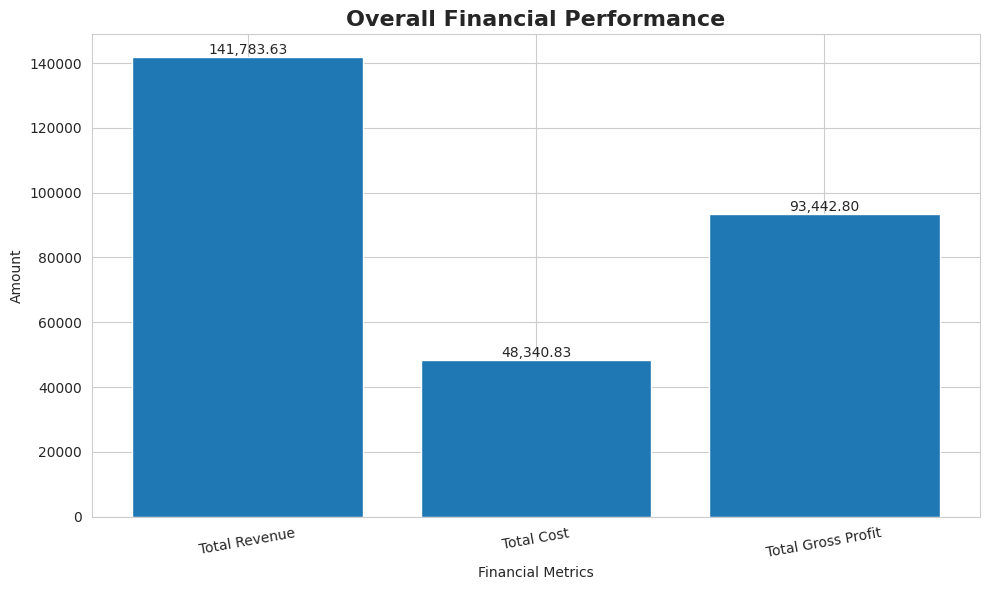

In [ ]:

# Visualizing overall financial performance

financial_metrics = [
    "Total Revenue",
    "Total Cost",
    "Total Gross Profit"
]

financial_values = [
    total_revenue,
    total_cost,
    total_gross_profit
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    financial_metrics,
    financial_values
)

plt.title(
    "Overall Financial Performance",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Financial Metrics")
plt.ylabel("Amount")
plt.xticks(rotation=10)

# Display values above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.2f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()


### 7.3 Sales Volume and Profitability Indicators

This section visualizes the total number of units sold and the overall gross margin percentage.

The visualization provides insights into sales volume and the company's ability to generate gross profit from its revenue.

These indicators help establish a baseline for further product-level and division-level profitability analysis.

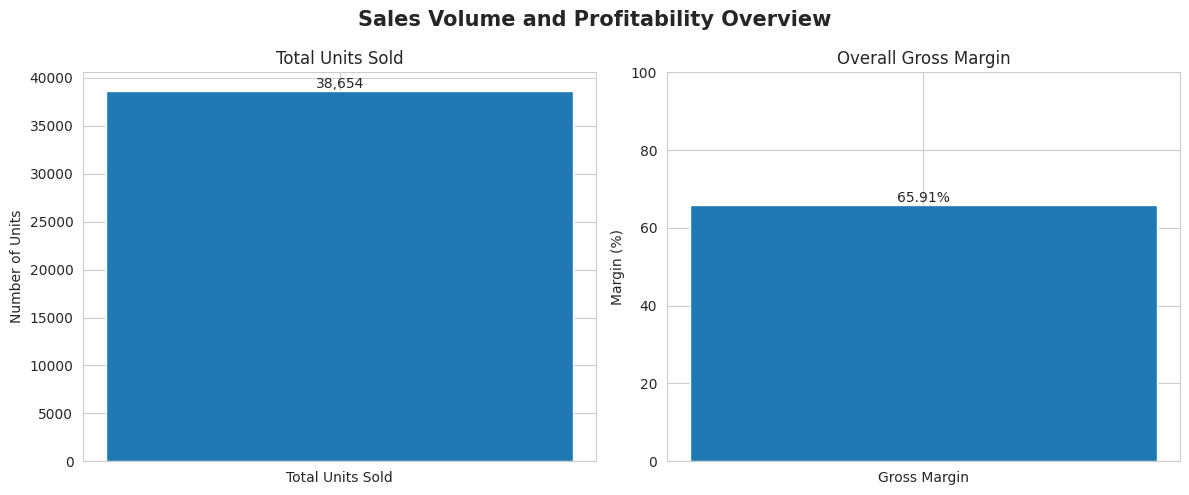

In [ ]:

# Visualizing units sold and overall gross margin

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Total Units Sold
axes[0].bar(
    ["Total Units Sold"],
    [total_units_sold]
)

axes[0].set_title("Total Units Sold")
axes[0].set_ylabel("Number of Units")

axes[0].text(
    0,
    total_units_sold,
    f"{total_units_sold:,.0f}",
    ha="center",
    va="bottom"
)

# Chart 2: Overall Gross Margin
axes[1].bar(
    ["Gross Margin"],
    [overall_gross_margin]
)

axes[1].set_title("Overall Gross Margin")
axes[1].set_ylabel("Margin (%)")
axes[1].set_ylim(0, 100)

axes[1].text(
    0,
    overall_gross_margin,
    f"{overall_gross_margin:.2f}%",
    ha="center",
    va="bottom"
)

plt.suptitle(
    "Sales Volume and Profitability Overview",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


## 8. Product-Level Profitability Analysis

This section evaluates the financial performance of individual products sold by Nassau Candy Distributor.

The analysis focuses on product-level revenue, cost, gross profit, sales volume and profitability.

It aims to identify high-performing products, products with strong profit margins and products that may require pricing or cost optimization.

### 8.1 Product-Level Performance Aggregation

Transaction-level records are grouped by Product ID and Product Name to calculate the overall financial performance of each product.

The aggregated results provide a consolidated view of product profitability across all transactions.

In [ ]:

# Aggregating financial performance by product

product_analysis = (
    df.groupby(["Product ID", "Product Name"])
    .agg({
        "Sales": "sum",
        "Cost": "sum",
        "Gross Profit": "sum",
        "Units": "sum"
    })
    .reset_index()
)

# Calculating product-level profitability KPIs

product_analysis["Gross Margin (%)"] = (
    product_analysis["Gross Profit"]
    / product_analysis["Sales"]
) * 100

product_analysis["Profit per Unit"] = (
    product_analysis["Gross Profit"]
    / product_analysis["Units"]
)

# Calculating product contribution

product_analysis["Revenue Contribution (%)"] = (
    product_analysis["Sales"] / total_revenue
) * 100

product_analysis["Profit Contribution (%)"] = (
    product_analysis["Gross Profit"] / total_gross_profit
) * 100

print("Product-level analysis completed successfully!")
print("Total Unique Products:", len(product_analysis))


Product-level analysis completed successfully!
Total Unique Products: 15


### 8.2 Product Profitability Summary

A consolidated product profitability table is generated to evaluate the financial performance of all 15 unique products.

The table includes total revenue, total cost, gross profit, units sold, gross margin, profit per unit and contribution to overall revenue and profit.

This comparison helps identify the products that contribute most significantly to the company's financial performance.

In [ ]:

# Creating a product profitability summary

product_summary = product_analysis[
    [
        "Product ID",
        "Product Name",
        "Sales",
        "Cost",
        "Gross Profit",
        "Units",
        "Gross Margin (%)",
        "Profit per Unit",
        "Revenue Contribution (%)",
        "Profit Contribution (%)"
    ]
].copy()

# Sorting products by gross profit

product_summary = product_summary.sort_values(
    by="Gross Profit",
    ascending=False
)

# Displaying the product profitability table

display(
    product_summary.style.format({
        "Sales": "{:,.2f}",
        "Cost": "{:,.2f}",
        "Gross Profit": "{:,.2f}",
        "Units": "{:,.0f}",
        "Gross Margin (%)": "{:.2f}%",
        "Profit per Unit": "{:.2f}",
        "Revenue Contribution (%)": "{:.2f}%",
        "Profit Contribution (%)": "{:.2f}%"
    })
)


,Product ID,Product Name,Sales,Cost,Gross Profit,Units,Gross Margin (%),Profit per Unit,Revenue Contribution (%),Profit Contribution (%)
3,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,"27,874.80","8,517.30","19,357.50","7,743",69.44%,2.50,19.66%,20.72%
4,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,"28,485.00","9,874.80","18,610.20","7,596",65.33%,2.45,20.09%,19.92%
1,CHO-MIL-31000,Wonka Bar - Milk Chocolate,"26,867.75","9,424.38","17,443.37","8,267",64.92%,2.11,18.95%,18.67%
2,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,"23,574.95","6,755.00","16,819.95","6,755",71.35%,2.49,16.63%,18.00%
0,CHO-FUD-51000,Wonka Bar - Fudge Mallows,"24,890.40","8,296.80","16,593.60","6,914",66.67%,2.40,17.56%,17.76%
8,OTH-LIC-15000,Lickable Wallpaper,"7,860.00","3,930.00","3,930.00",393,50.00%,10.00,5.54%,4.21%
6,OTH-GUM-21000,Wonka Gum,597.50,286.80,310.70,478,52.00%,0.65,0.42%,0.33%
9,SUG-EVE-47000,Everlasting Gobstopper,130.00,26.00,104.00,13,80.00%,8.00,0.09%,0.11%
7,OTH-KAZ-38000,Kazookles,"1,205.75","1,113.00",92.75,371,7.69%,0.25,0.85%,0.10%
11,SUG-HAI-55000,Hair Toffee,76.50,17.00,59.50,17,77.78%,3.50,0.05%,0.06%


### 8.3 Top 10 Products by Gross Profit

This analysis identifies the ten products generating the highest total gross profit.

Products are ranked in descending order of gross profit to highlight the major contributors to business profitability.

This analysis helps management understand which products are financially important and where sales and marketing efforts may be prioritized.

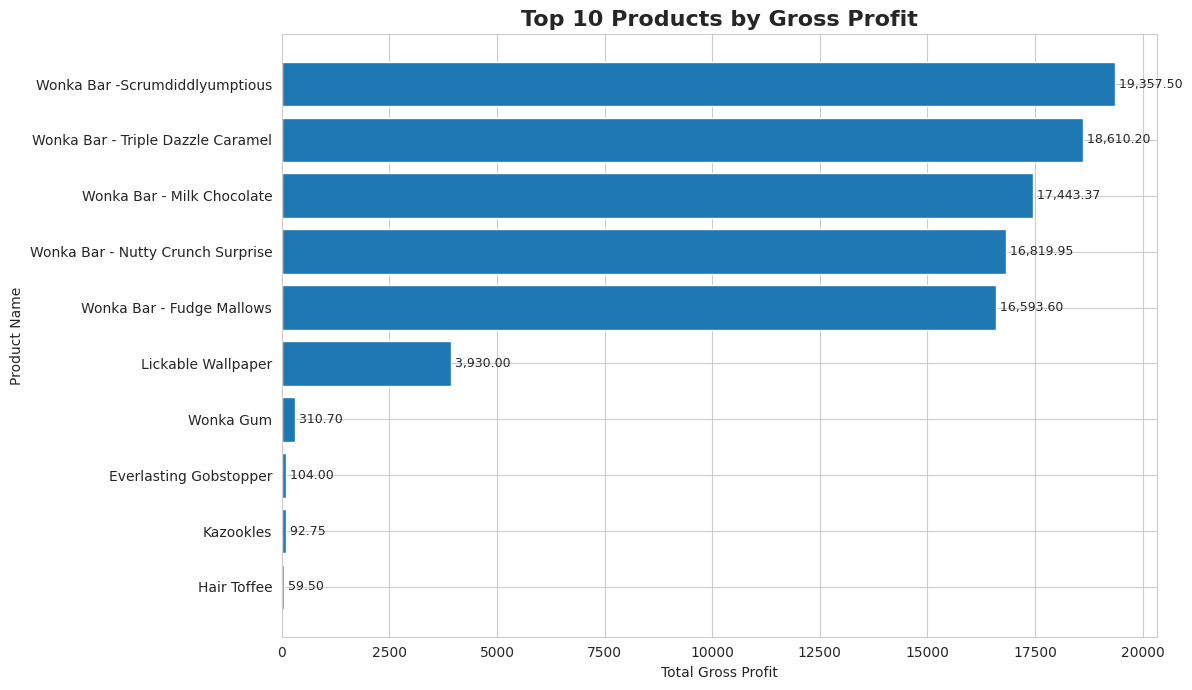

In [ ]:

# Identifying the top 10 products by gross profit

top_10_profit_products = (
    product_analysis
    .nlargest(10, "Gross Profit")
    .sort_values("Gross Profit", ascending=True)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_10_profit_products["Product Name"],
    top_10_profit_products["Gross Profit"]
)

plt.title(
    "Top 10 Products by Gross Profit",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Gross Profit")
plt.ylabel("Product Name")

# Adding profit values to bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:,.2f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()


### 8.4 Top 10 Products by Gross Margin (%)

This analysis identifies the ten products with the highest gross margin percentages.

Gross margin measures the percentage of revenue retained as gross profit after deducting product costs.

Ranking products by gross margin helps identify products that generate higher profitability relative to their sales revenue.

This analysis complements the gross profit ranking by highlighting profitability efficiency rather than total profit contribution.

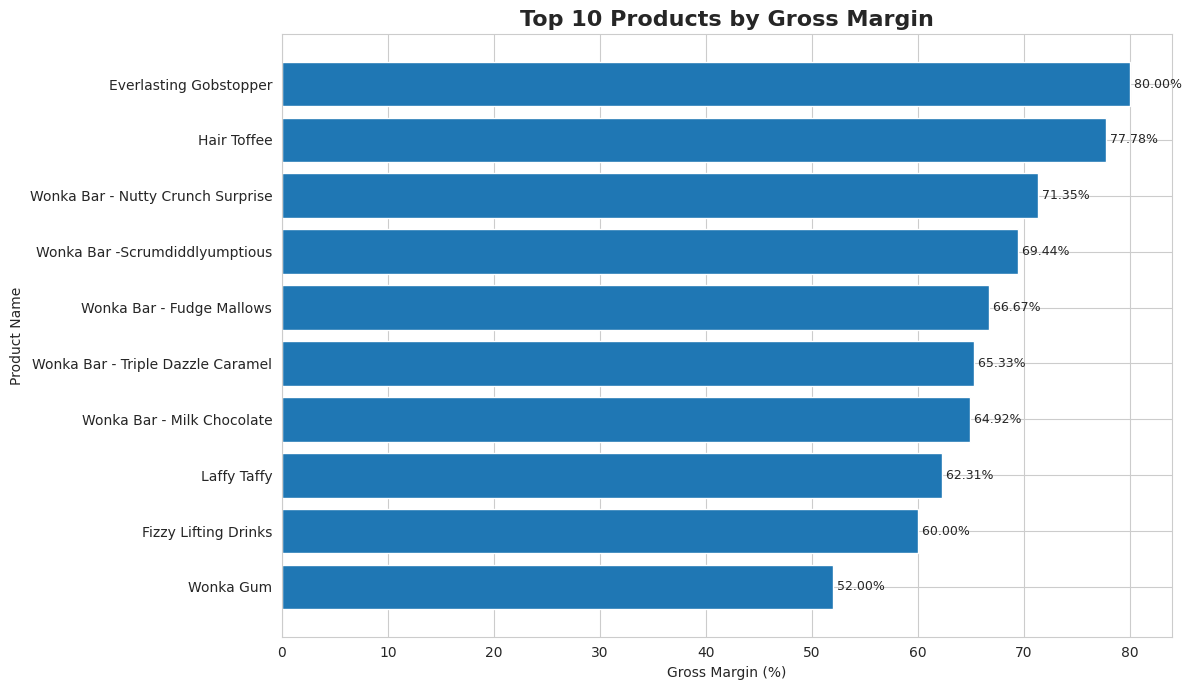

In [ ]:

# Identifying the top 10 products by gross margin

top_10_margin_products = (
    product_analysis
    .nlargest(10, "Gross Margin (%)")
    .sort_values("Gross Margin (%)", ascending=True)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_10_margin_products["Product Name"],
    top_10_margin_products["Gross Margin (%)"]
)

plt.title(
    "Top 10 Products by Gross Margin",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Gross Margin (%)")
plt.ylabel("Product Name")

# Adding margin percentages to bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:.2f}%",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()


### 8.5 Top 10 Products by Revenue

This analysis identifies the ten products generating the highest total revenue. It helps us understand which products contribute most to overall sales and compare their revenue performance with their profitability.

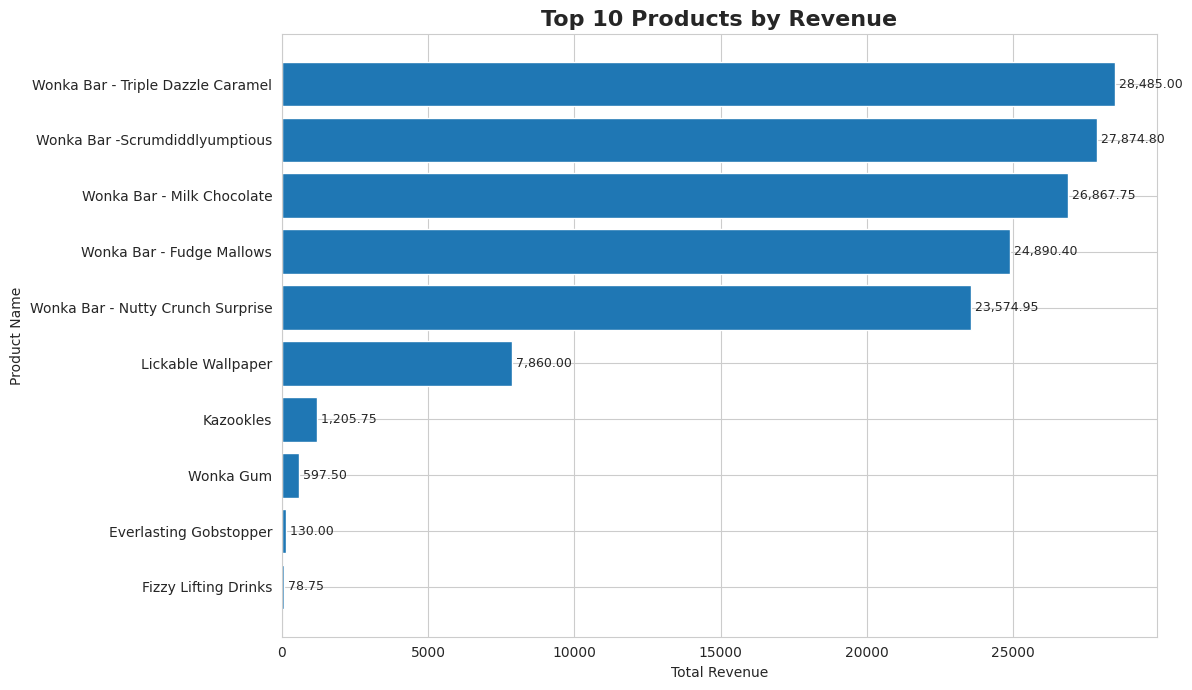

In [ ]:
top_10_revenue_products = (
    product_analysis
    .nlargest(10, "Sales")
    .sort_values("Sales", ascending=True)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_10_revenue_products["Product Name"],
    top_10_revenue_products["Sales"]
)

plt.title("Top 10 Products by Revenue", fontsize=16, fontweight="bold")
plt.xlabel("Total Revenue")
plt.ylabel("Product Name")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:,.2f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

### 8.6 Bottom 5 Products by Gross Margin

This analysis identifies the five products with the lowest gross margin percentages. These products may require further investigation into their selling prices, production costs, or pricing strategies.

Note: A low gross margin is a diagnostic indicator, not automatically evidence of poor business performance.

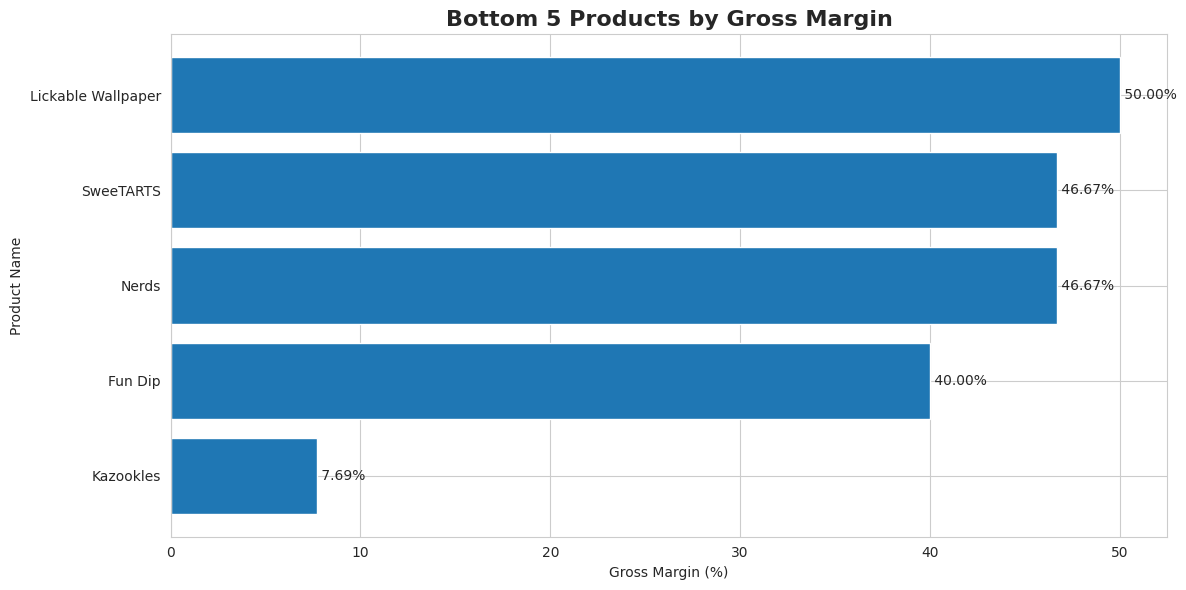

In [ ]:
bottom_5_margin_products = (
    product_analysis
    .nsmallest(5, "Gross Margin (%)")
    .sort_values("Gross Margin (%)", ascending=True)
)

plt.figure(figsize=(12, 6))

bars = plt.barh(
    bottom_5_margin_products["Product Name"],
    bottom_5_margin_products["Gross Margin (%)"]
)

plt.title("Bottom 5 Products by Gross Margin", fontsize=16, fontweight="bold")
plt.xlabel("Gross Margin (%)")
plt.ylabel("Product Name")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:.2f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

### 8.7 Top 10 Products by Profit per Unit

Profit per Unit measures the gross profit generated from each unit sold. This analysis identifies the products that generate the highest profit per unit and helps evaluate product-level profitability beyond total sales volume.

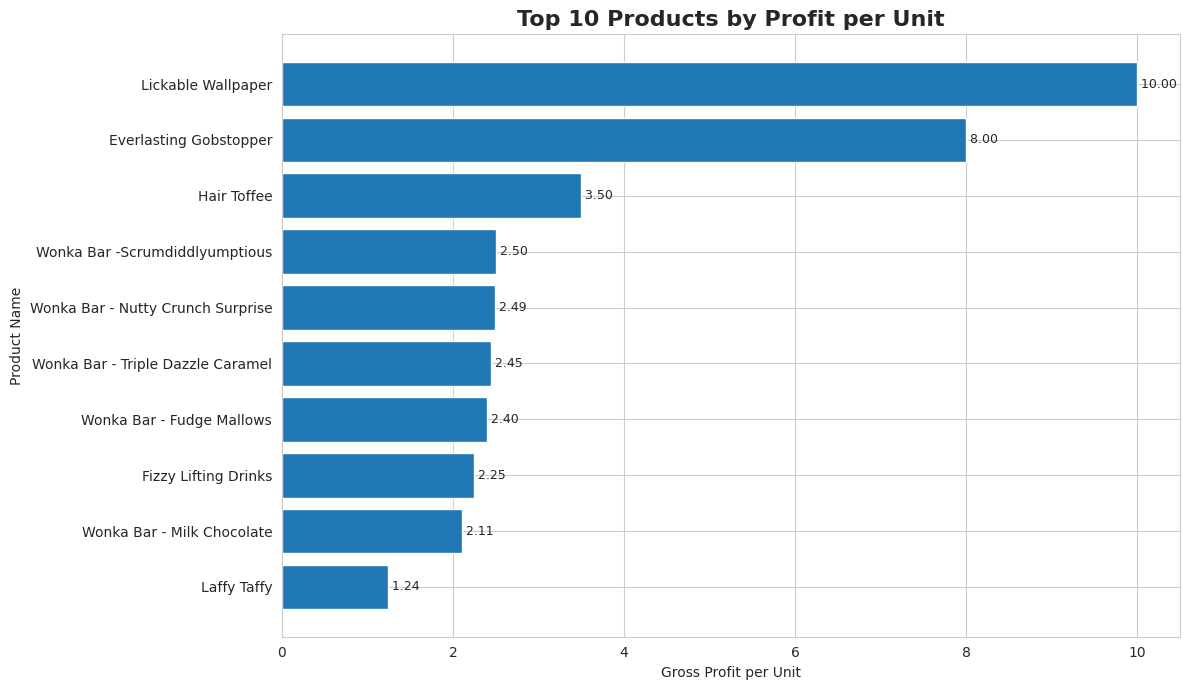

In [ ]:
top_10_profit_per_unit = (
    product_analysis
    .nlargest(10, "Profit per Unit")
    .sort_values("Profit per Unit", ascending=True)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_10_profit_per_unit["Product Name"],
    top_10_profit_per_unit["Profit per Unit"]
)

plt.title("Top 10 Products by Profit per Unit", fontsize=16, fontweight="bold")
plt.xlabel("Gross Profit per Unit")
plt.ylabel("Product Name")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:,.2f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

## 9. Division-Level Performance Analysis

This section evaluates the financial performance of each division. We will compare revenue, cost, gross profit, units sold, and gross margin to identify the strongest and weakest divisions.

In [ ]:
division_analysis = (
    df.groupby("Division")
    .agg({
        "Sales": "sum",
        "Cost": "sum",
        "Gross Profit": "sum",
        "Units": "sum"
    })
    .reset_index()
)

division_analysis["Gross Margin (%)"] = (
    division_analysis["Gross Profit"] / division_analysis["Sales"]
) * 100

division_analysis["Profit per Unit"] = (
    division_analysis["Gross Profit"] / division_analysis["Units"]
)

division_analysis["Revenue Contribution (%)"] = (
    division_analysis["Sales"] / total_revenue
) * 100

division_analysis["Profit Contribution (%)"] = (
    division_analysis["Gross Profit"] / total_gross_profit
) * 100

division_analysis = division_analysis.sort_values(
    "Gross Profit", ascending=False
)

print("Total Number of Divisions:", division_analysis["Division"].nunique())

display(
    division_analysis.round(2)
)

Total Number of Divisions: 3


,Division,Sales,Cost,Gross Profit,Units,Gross Margin (%),Profit per Unit,Revenue Contribution (%),Profit Contribution (%)
0,Chocolate,131692.90,42868.28,88824.62,37275,67.45,2.38,92.88,95.06
1,Other,9663.25,5329.80,4333.45,1242,44.84,3.49,6.82,4.64
2,Sugar,427.48,142.75,284.73,137,66.61,2.08,0.30,0.30


### 9.1 Gross Profit Comparison Across Divisions

This visualization compares the total gross profit generated by each division. It helps identify the divisions contributing the most to the company's overall profitability.

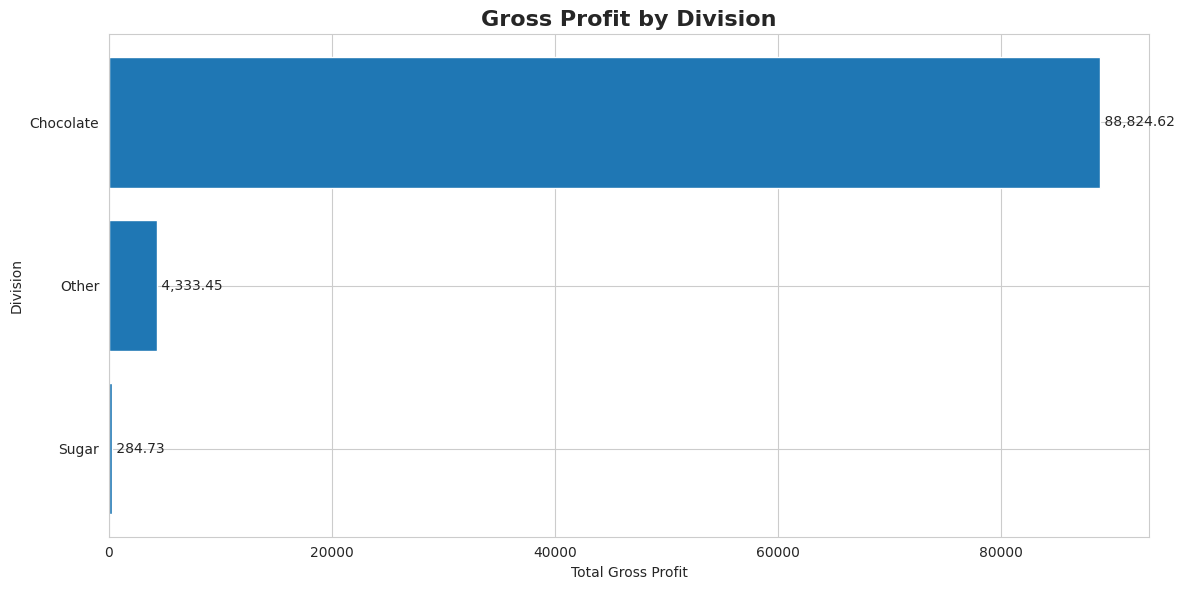

In [ ]:
division_profit_chart = division_analysis.sort_values(
    "Gross Profit", ascending=True
)

plt.figure(figsize=(12, 6))

bars = plt.barh(
    division_profit_chart["Division"],
    division_profit_chart["Gross Profit"]
)

plt.title("Gross Profit by Division", fontsize=16, fontweight="bold")
plt.xlabel("Total Gross Profit")
plt.ylabel("Division")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:,.2f}",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

### 9.2 Gross Margin Comparison Across Divisions

This visualization compares the gross margin percentage of each division. It helps identify which divisions retain the highest proportion of their revenue as gross profit after accounting for product costs.

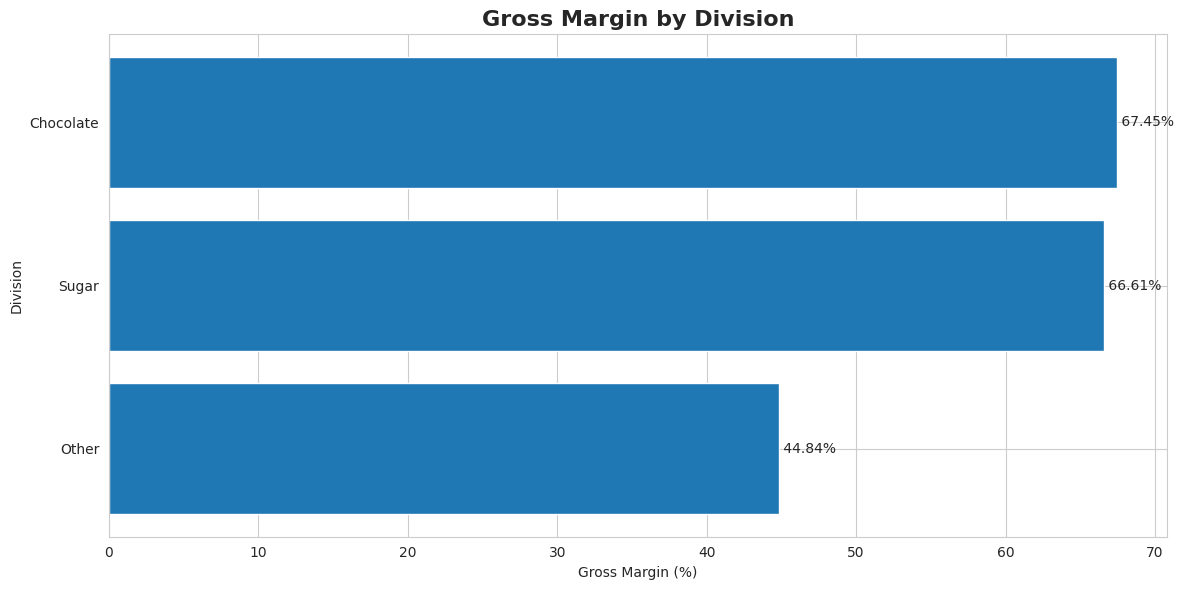

In [ ]:
division_margin_chart = division_analysis.sort_values(
    "Gross Margin (%)", ascending=True
)

plt.figure(figsize=(12, 6))

bars = plt.barh(
    division_margin_chart["Division"],
    division_margin_chart["Gross Margin (%)"]
)

plt.title("Gross Margin by Division", fontsize=16, fontweight="bold")
plt.xlabel("Gross Margin (%)")
plt.ylabel("Division")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:.2f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

### 9.3 Revenue vs Gross Profit by Division

This comparison visualizes total revenue and gross profit for each division. It helps evaluate the relationship between sales generation and profitability across different divisions.

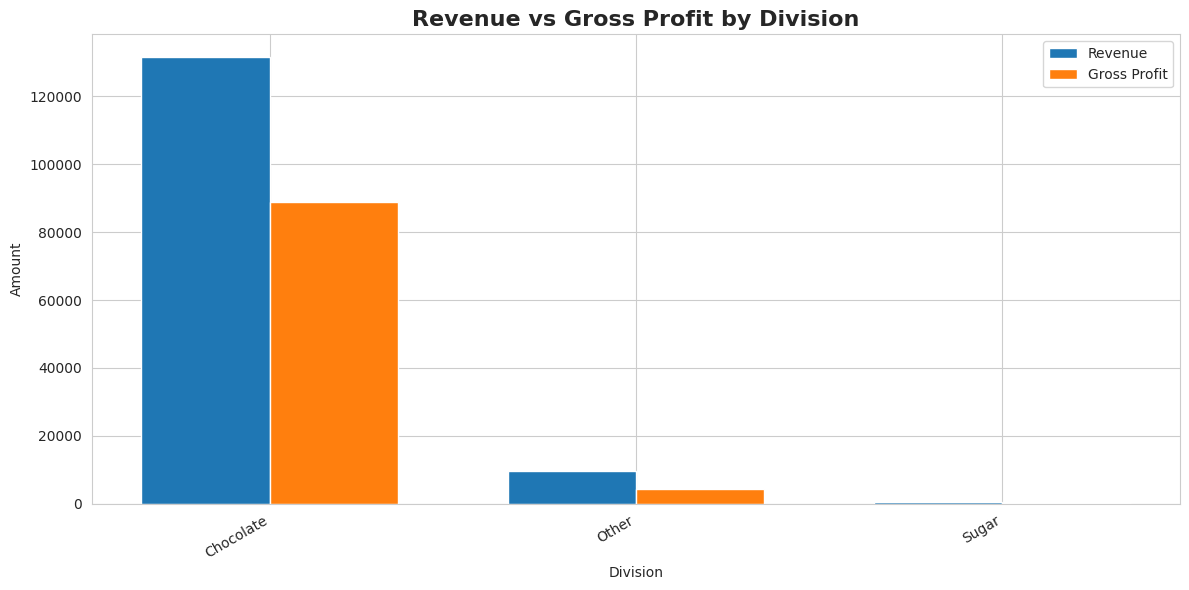

In [ ]:
division_comparison = division_analysis.sort_values(
    "Sales", ascending=False
)

x = np.arange(len(division_comparison))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    division_comparison["Sales"],
    width,
    label="Revenue"
)

plt.bar(
    x + width / 2,
    division_comparison["Gross Profit"],
    width,
    label="Gross Profit"
)

plt.title("Revenue vs Gross Profit by Division", fontsize=16, fontweight="bold")
plt.xlabel("Division")
plt.ylabel("Amount")
plt.xticks(x, division_comparison["Division"], rotation=30, ha="right")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Pareto Analysis – Product Profitability

Pareto Analysis helps identify the products that contribute most significantly to total gross profit.

The analysis ranks products from highest to lowest gross profit and calculates their cumulative profit contribution.

We will use the 80/20 principle as a reference to determine how many products contribute approximately 80% of total gross profit.

In [ ]:
pareto_profit = product_analysis.sort_values(
    "Gross Profit", ascending=False
).copy()

pareto_profit["Cumulative Profit (%)"] = (
    pareto_profit["Profit Contribution (%)"].cumsum()
)

pareto_profit["Product Rank"] = range(1, len(pareto_profit) + 1)

display(
    pareto_profit[
        [
            "Product Rank",
            "Product Name",
            "Gross Profit",
            "Profit Contribution (%)",
            "Cumulative Profit (%)"
        ]
    ].round(2)
)

,Product Rank,Product Name,Gross Profit,Profit Contribution (%),Cumulative Profit (%)
3,1,Wonka Bar -Scrumdiddlyumptious,19357.50,20.72,20.72
4,2,Wonka Bar - Triple Dazzle Caramel,18610.20,19.92,40.63
1,3,Wonka Bar - Milk Chocolate,17443.37,18.67,59.30
2,4,Wonka Bar - Nutty Crunch Surprise,16819.95,18.00,77.30
0,5,Wonka Bar - Fudge Mallows,16593.60,17.76,95.06
8,6,Lickable Wallpaper,3930.00,4.21,99.26
6,7,Wonka Gum,310.70,0.33,99.60
9,8,Everlasting Gobstopper,104.00,0.11,99.71
7,9,Kazookles,92.75,0.10,99.81
11,10,Hair Toffee,59.50,0.06,99.87


### 10.1 Pareto Chart – Cumulative Profit Contribution

This chart displays individual product gross profit alongside cumulative profit contribution.

The 80% reference line helps identify the number of products responsible for approximately 80% of total gross profit.

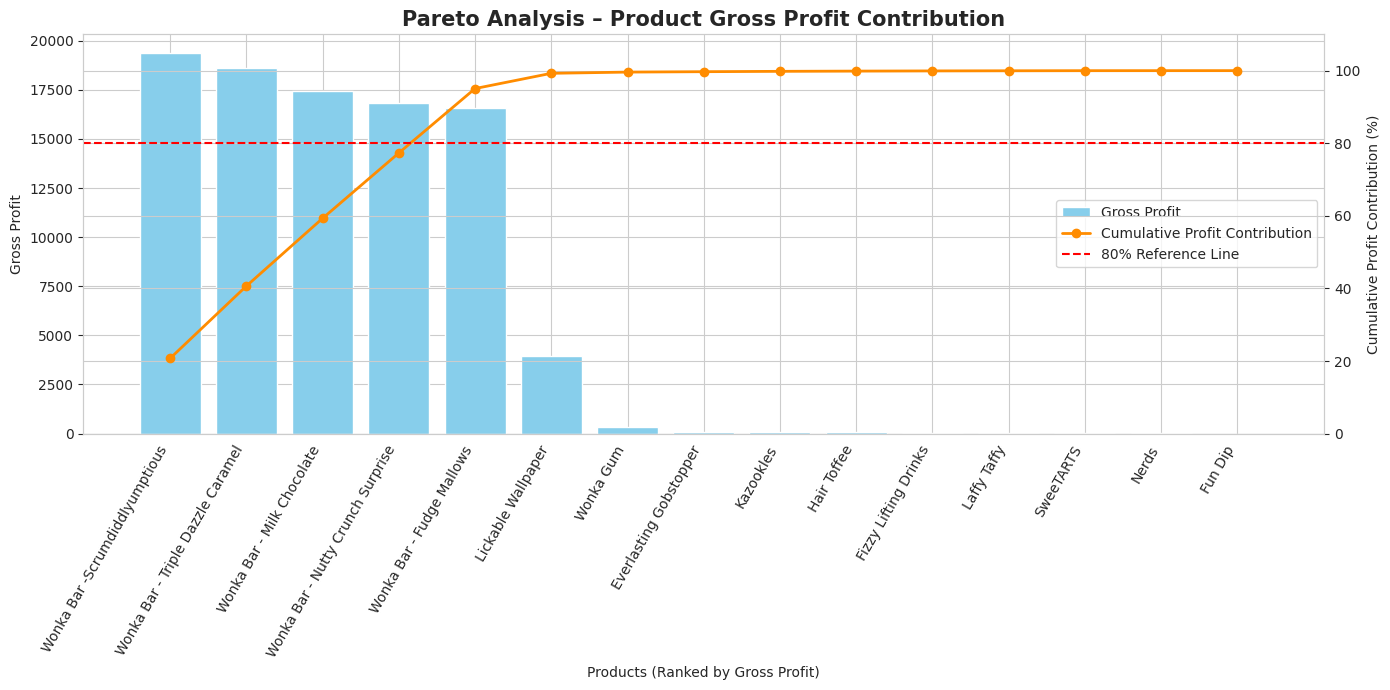

In [ ]:
fig, ax1 = plt.subplots(figsize=(14, 7))

x = np.arange(len(pareto_profit))

# Bars: individual product gross profit
ax1.bar(
    x,
    pareto_profit["Gross Profit"],
    color="skyblue",
    label="Gross Profit"
)

ax1.set_xlabel("Products (Ranked by Gross Profit)")
ax1.set_ylabel("Gross Profit")
ax1.set_title(
    "Pareto Analysis – Product Gross Profit Contribution",
    fontsize=15,
    fontweight="bold"
)

ax1.set_xticks(x)
ax1.set_xticklabels(
    pareto_profit["Product Name"],
    rotation=60,
    ha="right"
)

# Line: cumulative profit contribution
ax2 = ax1.twinx()

ax2.plot(
    x,
    pareto_profit["Cumulative Profit (%)"],
    marker="o",
    linewidth=2,
    color="darkorange",
    label="Cumulative Profit Contribution"
)

ax2.axhline(
    y=80,
    linestyle="--",
    color="red",
    label="80% Reference Line"
)

ax2.set_ylabel("Cumulative Profit Contribution (%)")
ax2.set_ylim(0, 110)

# Combined legend
bars, labels = ax1.get_legend_handles_labels()
lines, line_labels = ax2.get_legend_handles_labels()

ax1.legend(
    bars + lines,
    labels + line_labels,
    loc="center right"
)

plt.tight_layout()
plt.show()

In [ ]:
products_for_80_profit = (
    pareto_profit["Cumulative Profit (%)"] < 80
).sum() + 1

actual_profit_contribution = pareto_profit.loc[
    products_for_80_profit - 1,
    "Cumulative Profit (%)"
]

print("Total Products:", len(pareto_profit))
print("Products Required to Reach at Least 80% of Profit:", products_for_80_profit)
print(f"Actual Cumulative Profit Contribution: {actual_profit_contribution:.2f}%")

Total Products: 15
Products Required to Reach at Least 80% of Profit: 5
Actual Cumulative Profit Contribution: 40.63%


## 11. Cost and Margin Diagnostics

This section examines the relationship between product costs, sales revenue, and gross margins.

The cost-to-sales ratio helps identify products where a relatively large proportion of revenue is consumed by costs.

In [ ]:
product_analysis["Cost Ratio (%)"] = (
    product_analysis["Cost"] / product_analysis["Sales"]
) * 100

cost_ratio_analysis = product_analysis.sort_values(
    "Cost Ratio (%)", ascending=False
)

display(
    cost_ratio_analysis[
        [
            "Product Name",
            "Sales",
            "Cost",
            "Gross Profit",
            "Cost Ratio (%)",
            "Gross Margin (%)"
        ]
    ].round(2)
)

,Product Name,Sales,Cost,Gross Profit,Cost Ratio (%),Gross Margin (%)
7,Kazookles,1205.75,1113.00,92.75,92.31,7.69
10,Fun Dip,12.00,7.20,4.80,60.00,40.00
13,Nerds,15.00,8.00,7.00,53.33,46.67
14,SweeTARTS,61.50,32.80,28.70,53.33,46.67
8,Lickable Wallpaper,7860.00,3930.00,3930.00,50.00,50.00
6,Wonka Gum,597.50,286.80,310.70,48.00,52.00
5,Fizzy Lifting Drinks,78.75,31.50,47.25,40.00,60.00
12,Laffy Taffy,53.73,20.25,33.48,37.69,62.31
1,Wonka Bar - Milk Chocolate,26867.75,9424.38,17443.37,35.08,64.92
4,Wonka Bar - Triple Dazzle Caramel,28485.00,9874.80,18610.20,34.67,65.33


### 11.1 Relationship Between Sales and Gross Profit

This scatter plot examines the relationship between total sales revenue and gross profit across products.

It helps identify products with high revenue and high profit, as well as products generating comparatively lower profit despite their sales.

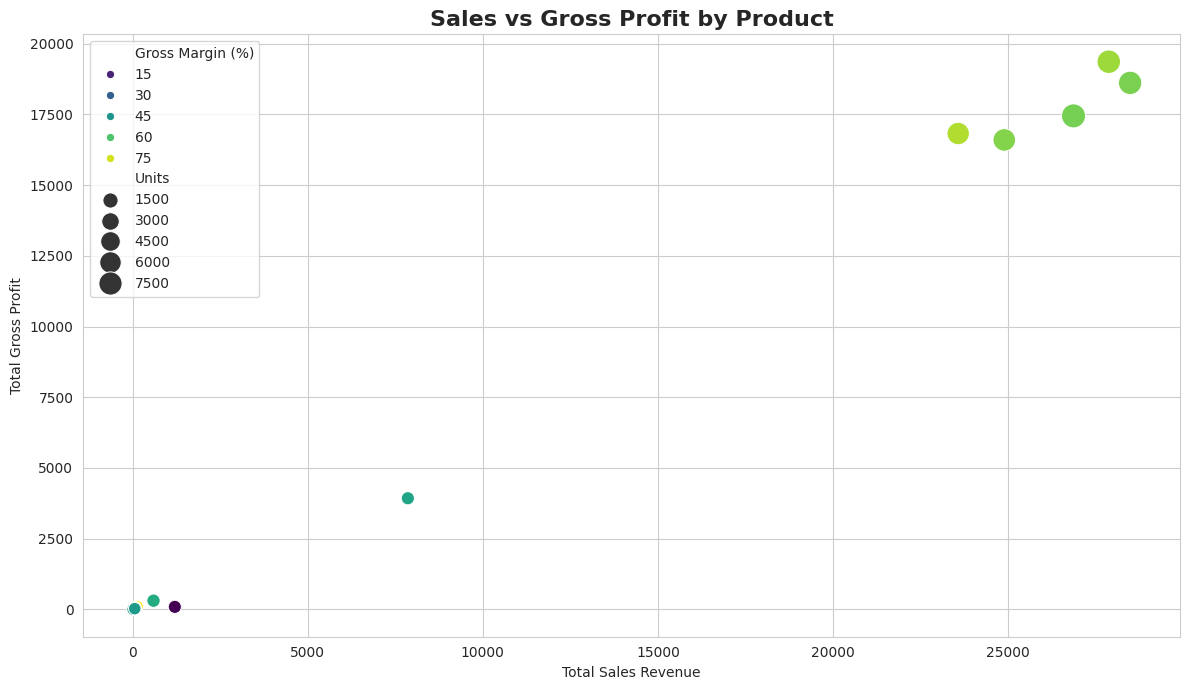

In [ ]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=product_analysis,
    x="Sales",
    y="Gross Profit",
    hue="Gross Margin (%)",
    size="Units",
    sizes=(80, 300),
    palette="viridis",
    legend="brief"
)

plt.title(
    "Sales vs Gross Profit by Product",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Sales Revenue")
plt.ylabel("Total Gross Profit")

plt.tight_layout()
plt.show()

### 11.2 Distribution of Gross Margin Across Products

This analysis examines the distribution of gross margin percentages across all products.

A histogram helps identify the range in which most product margins fall, while making it easier to identify products with comparatively high or low margins.

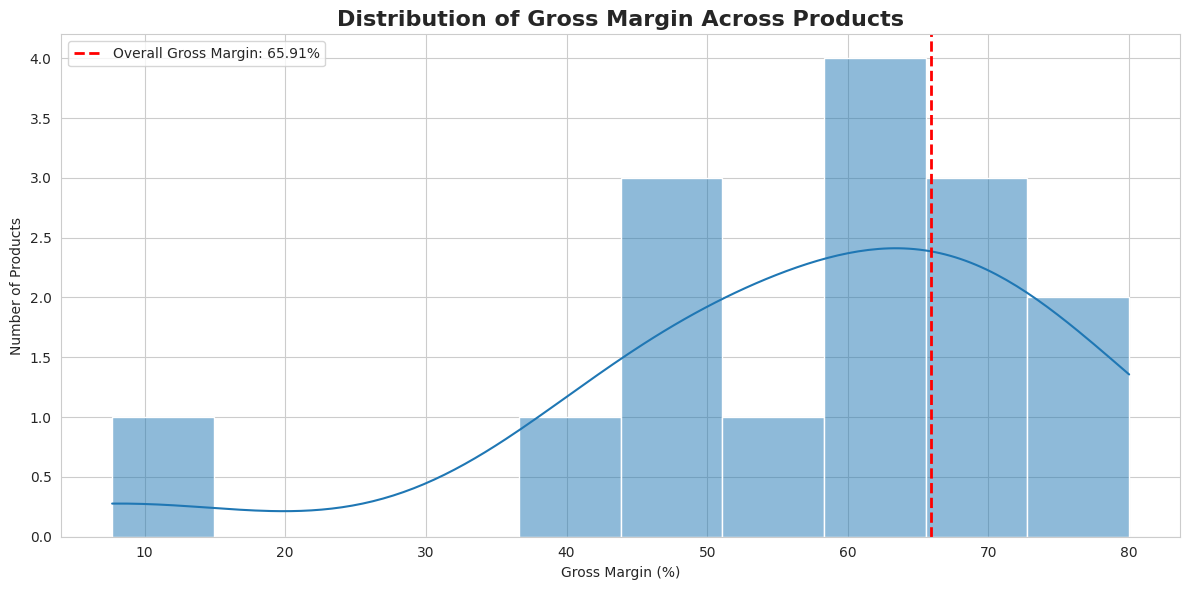

In [ ]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=product_analysis,
    x="Gross Margin (%)",
    bins=10,
    kde=True
)

plt.axvline(
    overall_gross_margin,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall Gross Margin: {overall_gross_margin:.2f}%"
)

plt.title(
    "Distribution of Gross Margin Across Products",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Gross Margin (%)")
plt.ylabel("Number of Products")
plt.legend()

plt.tight_layout()
plt.show()

### 11.3 Gross Margin Variation and Outlier Analysis

A box plot provides a summary of the distribution of gross margins across products.

It displays the median, quartiles, overall spread, and any potential outliers. This helps identify products whose margins differ considerably from the rest.

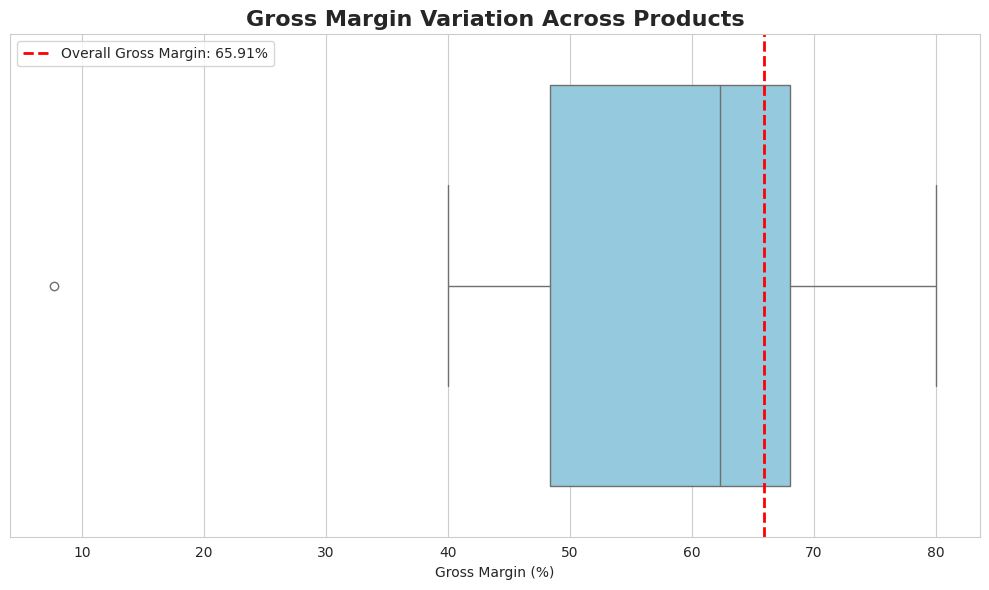

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x=product_analysis["Gross Margin (%)"],
    color="skyblue"
)

plt.axvline(
    overall_gross_margin,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall Gross Margin: {overall_gross_margin:.2f}%"
)

plt.title(
    "Gross Margin Variation Across Products",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Gross Margin (%)")
plt.legend()

plt.tight_layout()
plt.show()

## 12. Time-Based Sales and Profitability Analysis

This section examines the monthly performance of the business over the available reporting period.

We will analyse monthly revenue, cost, gross profit, units sold, and gross margin to identify changes in sales and profitability over time.

In [ ]:
# Create a monthly period column
df["Order Month"] = df["Order Date"].dt.to_period("M")

# Aggregate financial performance by month
monthly_analysis = (
    df.groupby("Order Month")
    .agg({
        "Sales": "sum",
        "Cost": "sum",
        "Gross Profit": "sum",
        "Units": "sum"
    })
    .reset_index()
)

# Calculate monthly gross margin
monthly_analysis["Gross Margin (%)"] = (
    monthly_analysis["Gross Profit"] / monthly_analysis["Sales"]
) * 100

# Convert monthly periods into strings for plotting
monthly_analysis["Month"] = monthly_analysis["Order Month"].astype(str)

print("Total Months Analysed:", len(monthly_analysis))

display(monthly_analysis.round(2))

Total Months Analysed: 24


,Order Month,Sales,Cost,Gross Profit,Units,Gross Margin (%),Month
0,2024-01,2093.90,727.76,1366.14,566,65.24,2024-01
1,2024-02,1379.87,471.28,908.59,398,65.85,2024-02
2,2024-03,4138.90,1467.74,2671.16,1125,64.54,2024-03
3,2024-04,3988.22,1375.41,2612.81,1079,65.51,2024-04
4,2024-05,3951.52,1336.08,2615.44,1099,66.19,2024-05
5,2024-06,3518.76,1188.04,2330.72,1010,66.24,2024-06
6,2024-07,3865.38,1300.12,2565.26,1107,66.37,2024-07
7,2024-08,4477.65,1531.78,2945.87,1227,65.79,2024-08
8,2024-09,7912.10,2705.40,5206.70,2105,65.81,2024-09
9,2024-10,4815.98,1696.52,3119.46,1237,64.77,2024-10


### 12.1 Monthly Revenue Trend

This line chart illustrates the movement of monthly sales revenue over the reporting period.

It helps identify months with higher or lower sales activity and provides an overview of revenue performance over time.

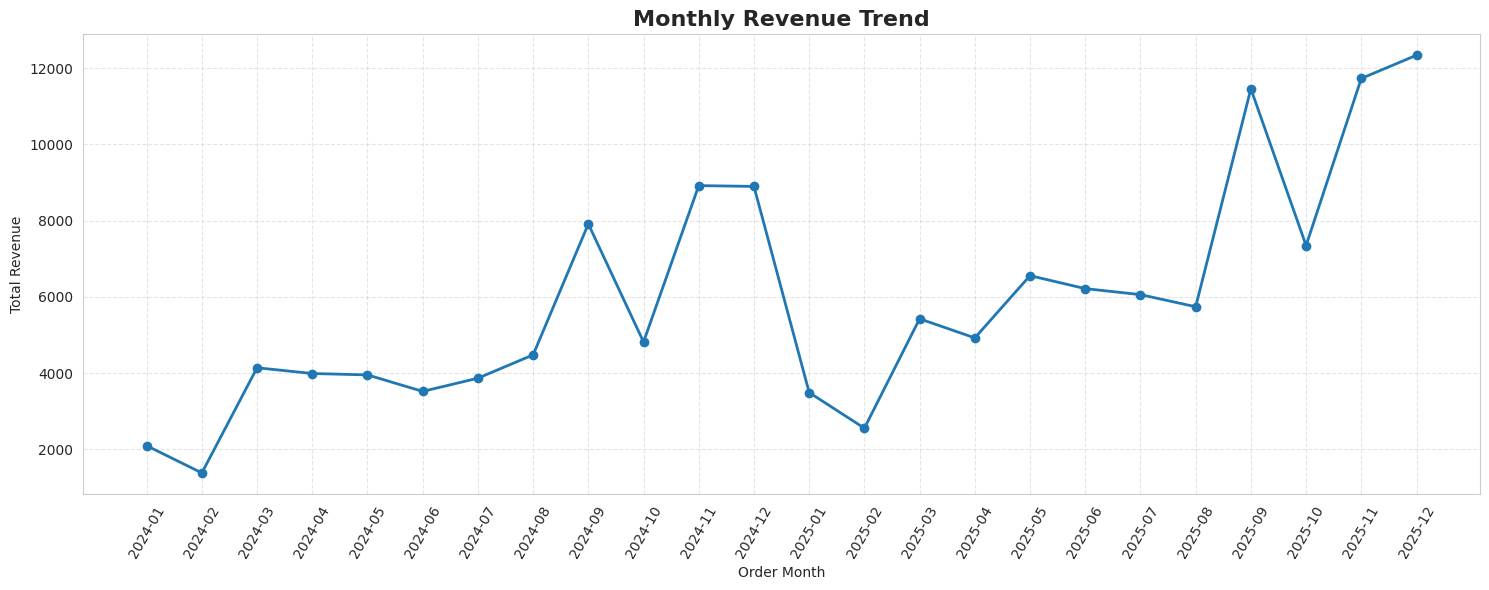

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Sales"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Revenue Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Order Month")
plt.ylabel("Total Revenue")

plt.xticks(rotation=60)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 12.2 Monthly Gross Profit Trend

This line chart illustrates the monthly gross profit generated by the business.

Comparing monthly gross profit with the revenue trend helps us understand whether higher sales are also translating into higher profitability.

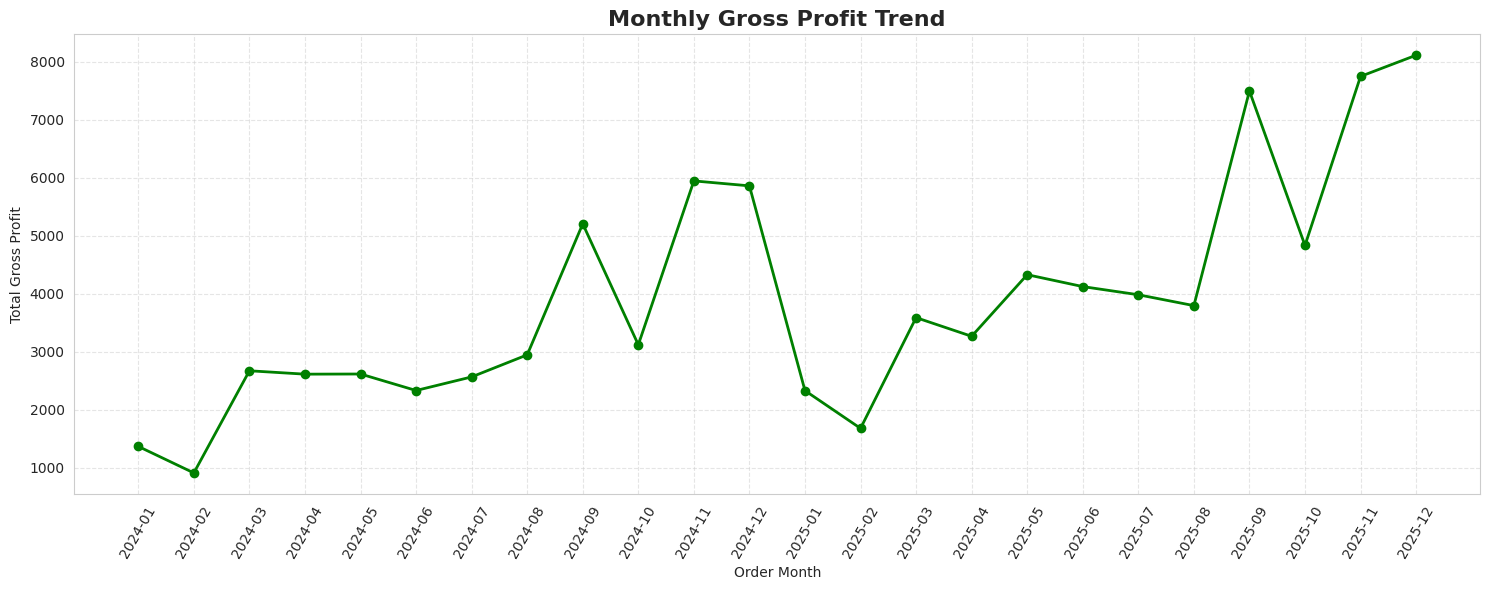

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Gross Profit"],
    marker="o",
    linewidth=2,
    color="green"
)

plt.title(
    "Monthly Gross Profit Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Order Month")
plt.ylabel("Total Gross Profit")

plt.xticks(rotation=60)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 12.3 Monthly Gross Margin Trend

This line chart examines how the gross margin percentage changes over time.

It helps identify months with relatively stronger or weaker profitability and reveals whether the business maintains a consistent gross margin throughout the reporting period.

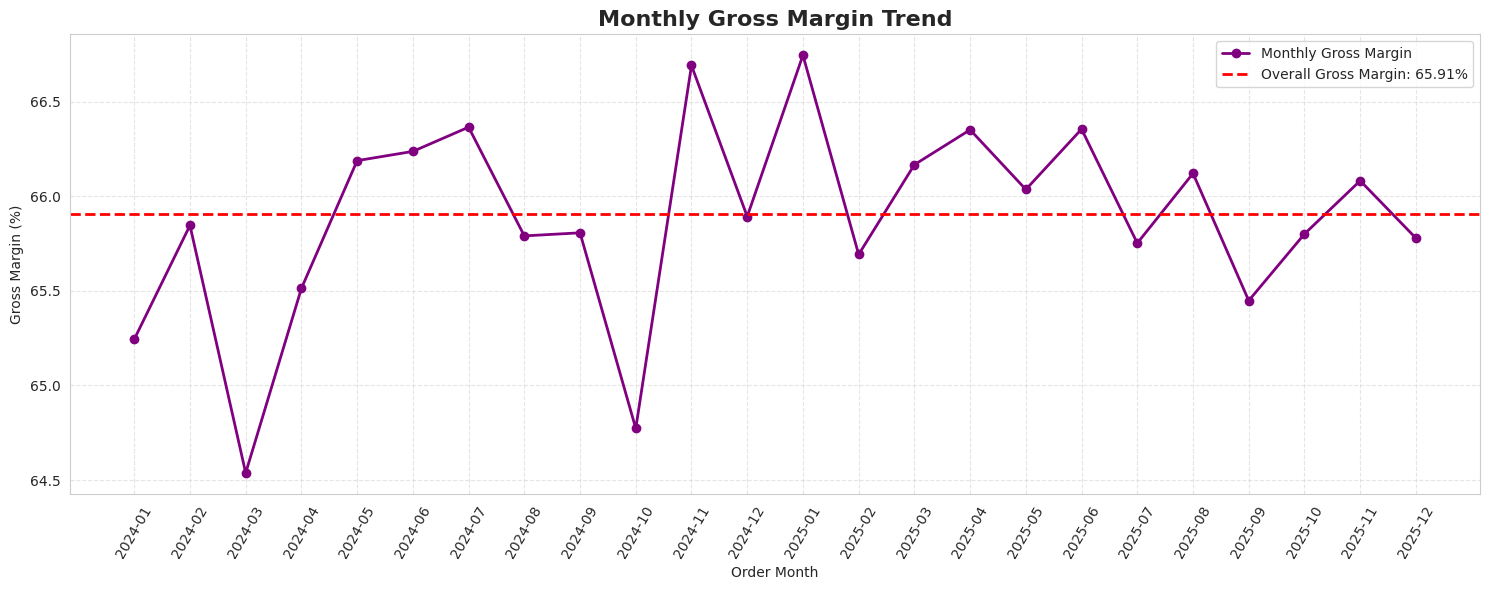

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Gross Margin (%)"],
    marker="o",
    linewidth=2,
    color="purple",
    label="Monthly Gross Margin"
)

plt.axhline(
    overall_gross_margin,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall Gross Margin: {overall_gross_margin:.2f}%"
)

plt.title(
    "Monthly Gross Margin Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Order Month")
plt.ylabel("Gross Margin (%)")

plt.xticks(rotation=60)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

### 12.4 Monthly Gross Margin Volatility

Margin volatility measures the variation in gross margin percentages over the reporting period.

We use the standard deviation of monthly gross margins to understand how consistently the business maintains its profitability.

A lower standard deviation indicates more consistent monthly margins, while a higher standard deviation indicates greater fluctuations.

In [ ]:
# Calculate monthly gross margin volatility
margin_volatility = monthly_analysis["Gross Margin (%)"].std()

# Calculate average monthly gross margin
average_monthly_margin = monthly_analysis["Gross Margin (%)"].mean()

# Calculate minimum and maximum monthly margins
minimum_monthly_margin = monthly_analysis["Gross Margin (%)"].min()
maximum_monthly_margin = monthly_analysis["Gross Margin (%)"].max()

print("MONTHLY GROSS MARGIN VOLATILITY")
print("-" * 40)

print(f"Average Monthly Gross Margin: {average_monthly_margin:.2f}%")
print(f"Margin Standard Deviation: {margin_volatility:.2f} percentage points")
print(f"Minimum Monthly Gross Margin: {minimum_monthly_margin:.2f}%")
print(f"Maximum Monthly Gross Margin: {maximum_monthly_margin:.2f}%")
print(f"Number of Months Analysed: {len(monthly_analysis)}")

MONTHLY GROSS MARGIN VOLATILITY
----------------------------------------
Average Monthly Gross Margin: 65.88%
Margin Standard Deviation: 0.53 percentage points
Minimum Monthly Gross Margin: 64.54%
Maximum Monthly Gross Margin: 66.75%
Number of Months Analysed: 24


### 12.5 Product-Level Gross Margin Volatility

This analysis measures the variation in monthly gross margin for each product.

It helps identify products with consistent profitability and products whose margins fluctuate considerably over time.

Products with only one month of recorded sales cannot have their monthly margin volatility calculated, so they will be excluded from the volatility ranking.

In [ ]:
# Calculate monthly performance for each product
product_monthly = (
    df.groupby(["Product ID", "Product Name", "Order Month"])
    .agg({
        "Sales": "sum",
        "Gross Profit": "sum"
    })
    .reset_index()
)

# Calculate each product's monthly gross margin
product_monthly["Gross Margin (%)"] = (
    product_monthly["Gross Profit"] / product_monthly["Sales"]
) * 100

# Calculate margin volatility for each product
product_margin_volatility = (
    product_monthly.groupby(["Product ID", "Product Name"])
    .agg(
        Margin_Volatility=("Gross Margin (%)", "std"),
        Months_Observed=("Gross Margin (%)", "count"),
        Average_Monthly_Margin=("Gross Margin (%)", "mean")
    )
    .reset_index()
)

# Keep products with at least two months of observations
product_margin_volatility = (
    product_margin_volatility[
        product_margin_volatility["Months_Observed"] >= 2
    ]
    .sort_values("Margin_Volatility", ascending=False)
)

product_margin_volatility = product_margin_volatility.rename(
    columns={
        "Margin_Volatility": "Margin Volatility (Percentage Points)",
        "Months_Observed": "Months Observed",
        "Average_Monthly_Margin": "Average Monthly Margin (%)"
    }
)

print("Product-Level Margin Volatility")
print("-" * 45)

display(product_margin_volatility.round(2))

Product-Level Margin Volatility
---------------------------------------------


,Product ID,Product Name,Margin Volatility (Percentage Points),Months Observed,Average Monthly Margin (%)
0,CHO-FUD-51000,Wonka Bar - Fudge Mallows,0.0,24,66.67
1,CHO-MIL-31000,Wonka Bar - Milk Chocolate,0.0,24,64.92
3,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,0.0,24,69.44
4,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,0.0,24,65.33
6,OTH-GUM-21000,Wonka Gum,0.0,24,52.00
2,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,0.0,24,71.35
5,OTH-FIZ-56000,Fizzy Lifting Drinks,0.0,5,60.00
7,OTH-KAZ-38000,Kazookles,0.0,23,7.69
8,OTH-LIC-15000,Lickable Wallpaper,0.0,20,50.00
9,SUG-EVE-47000,Everlasting Gobstopper,0.0,3,80.00


### 12.6 Products with the Highest Margin Volatility

This visualization identifies the ten products with the highest month-to-month gross margin fluctuations.

It helps management identify products that may require closer monitoring of selling prices and costs to maintain consistent profitability.

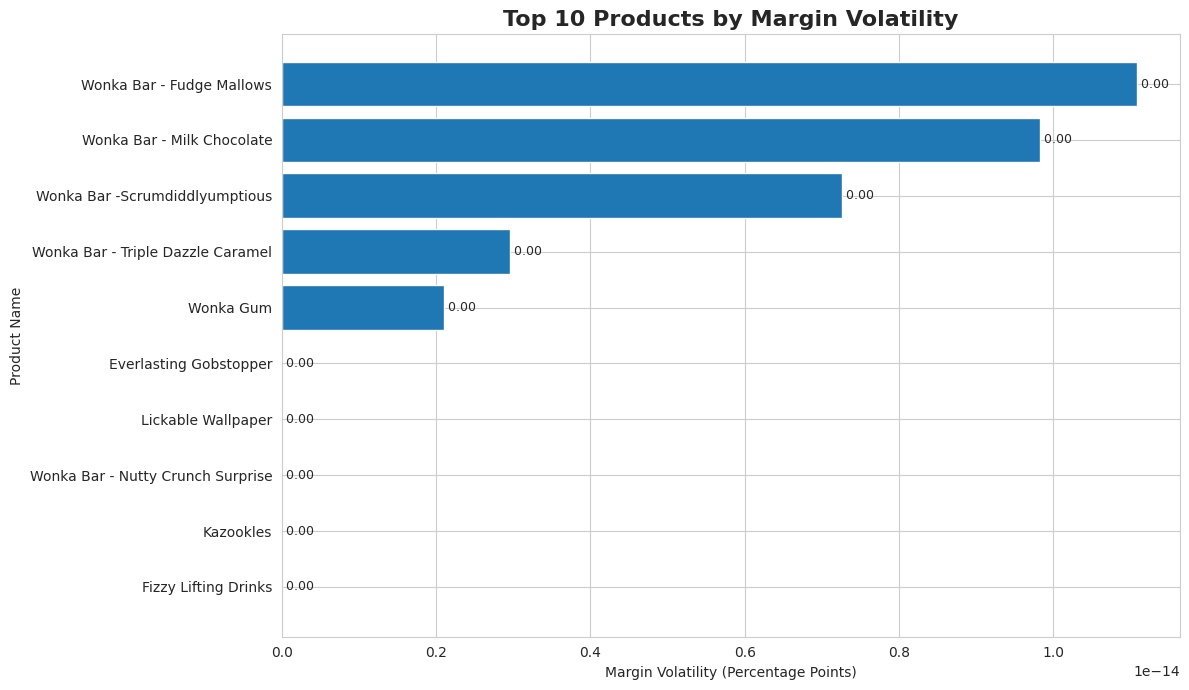

In [ ]:
top_10_volatile_products = (
    product_margin_volatility
    .nlargest(10, "Margin Volatility (Percentage Points)")
    .sort_values("Margin Volatility (Percentage Points)", ascending=True)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_10_volatile_products["Product Name"],
    top_10_volatile_products["Margin Volatility (Percentage Points)"]
)

plt.title(
    "Top 10 Products by Margin Volatility",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Margin Volatility (Percentage Points)")
plt.ylabel("Product Name")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:.2f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

## 13. Key Business Insights and Recommendations

This section consolidates the most important financial and operational performance indicators identified during the analysis.

These KPIs will serve as the foundation for developing data-driven business insights and recommendations.

In [ ]:
# Create a consolidated KPI summary

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Cost",
        "Total Gross Profit",
        "Total Units Sold",
        "Overall Gross Margin (%)",
        "Average Selling Price per Unit",
        "Average Gross Profit per Unit",
        "Monthly Gross Margin Volatility (Percentage Points)",
        "Number of Products",
        "Number of Divisions",
        "Number of Months Analysed"
    ],
    "Value": [
        total_revenue,
        total_cost,
        total_gross_profit,
        total_units_sold,
        overall_gross_margin,
        average_selling_price,
        average_profit_per_unit,
        margin_volatility,
        product_analysis["Product ID"].nunique(),
        division_analysis["Division"].nunique(),
        len(monthly_analysis)
    ]
})

display(kpi_summary.round(2))

,KPI,Value
0,Total Revenue,141783.63
1,Total Cost,48340.83
2,Total Gross Profit,93442.80
3,Total Units Sold,38654.00
4,Overall Gross Margin (%),65.91
5,Average Selling Price per Unit,3.67
6,Average Gross Profit per Unit,2.42
7,Monthly Gross Margin Volatility (Percentage Po...,0.53
8,Number of Products,15.00
9,Number of Divisions,3.00


### 13.1 Identification of Best and Weakest Performers

This analysis identifies the strongest and weakest performers across products and divisions.

We evaluate performance using gross profit, gross margin, and profit per unit. This provides a more comprehensive understanding than relying on revenue alone.

In [ ]:
# Best and weakest products

best_product_profit = product_analysis.loc[
    product_analysis["Gross Profit"].idxmax()
]

lowest_product_profit = product_analysis.loc[
    product_analysis["Gross Profit"].idxmin()
]

best_product_margin = product_analysis.loc[
    product_analysis["Gross Margin (%)"].idxmax()
]

lowest_product_margin = product_analysis.loc[
    product_analysis["Gross Margin (%)"].idxmin()
]

# Best and weakest divisions

best_division_profit = division_analysis.loc[
    division_analysis["Gross Profit"].idxmax()
]

lowest_division_profit = division_analysis.loc[
    division_analysis["Gross Profit"].idxmin()
]

best_division_margin = division_analysis.loc[
    division_analysis["Gross Margin (%)"].idxmax()
]

lowest_division_margin = division_analysis.loc[
    division_analysis["Gross Margin (%)"].idxmin()
]

# Display findings

print("PRODUCT PERFORMANCE")
print("=" * 50)

print(
    f"Highest Gross Profit: {best_product_profit['Product Name']} "
    f"({best_product_profit['Gross Profit']:,.2f})"
)

print(
    f"Lowest Gross Profit: {lowest_product_profit['Product Name']} "
    f"({lowest_product_profit['Gross Profit']:,.2f})"
)

print(
    f"Highest Gross Margin: {best_product_margin['Product Name']} "
    f"({best_product_margin['Gross Margin (%)']:.2f}%)"
)

print(
    f"Lowest Gross Margin: {lowest_product_margin['Product Name']} "
    f"({lowest_product_margin['Gross Margin (%)']:.2f}%)"
)

print("\nDIVISION PERFORMANCE")
print("=" * 50)

print(
    f"Highest Gross Profit: {best_division_profit['Division']} "
    f"({best_division_profit['Gross Profit']:,.2f})"
)

print(
    f"Lowest Gross Profit: {lowest_division_profit['Division']} "
    f"({lowest_division_profit['Gross Profit']:,.2f})"
)

print(
    f"Highest Gross Margin: {best_division_margin['Division']} "
    f"({best_division_margin['Gross Margin (%)']:.2f}%)"
)

print(
    f"Lowest Gross Margin: {lowest_division_margin['Division']} "
    f"({lowest_division_margin['Gross Margin (%)']:.2f}%)"
)

PRODUCT PERFORMANCE
Highest Gross Profit: Wonka Bar -Scrumdiddlyumptious (19,357.50)
Lowest Gross Profit: Fun Dip (4.80)
Highest Gross Margin: Everlasting Gobstopper (80.00%)
Lowest Gross Margin: Kazookles (7.69%)

DIVISION PERFORMANCE
Highest Gross Profit: Chocolate (88,824.62)
Lowest Gross Profit: Sugar (284.73)
Highest Gross Margin: Chocolate (67.45%)
Lowest Gross Margin: Other (44.84%)


### 13.2 Key Business Insights

Based on the product-level and division-level profitability analysis, the following insights were identified:

1. Product Profitability:
   Wonka Bar - Scrumdiddlyumptious generated the highest total gross profit of 19,357.50, making it the leading product in terms of total profit contribution.

2. Product Margin Performance:
   Everlasting Gobstopper achieved the highest gross margin of 80%, indicating strong profitability relative to its revenue.

3. Low-Margin Product:
   Kazookles recorded the lowest gross margin of 7.69%. Its pricing strategy and associated costs require further investigation.

4. Division Profitability:
   Chocolate was the strongest-performing division, generating 88,824.62 in gross profit.

5. Division Margin Performance:
   Chocolate also achieved the highest gross margin of 67.45%, demonstrating strong performance in both profit generation and margin retention.

6. Division Requiring Attention:
   The Other division recorded the lowest gross margin of 44.84%, suggesting an opportunity to review its product costs and pricing.

7. Low-Profit Division:
   Sugar generated the lowest total gross profit of 284.73. Further investigation of its revenue, sales volume, and product mix is required before making operational decisions.

### 13.3 Business Recommendations

Based on the findings, the following recommendations are proposed:

1. Review Low-Margin Products:
   Investigate Kazookles to understand its cost structure and pricing. Identify opportunities to reduce costs or improve its selling price without negatively affecting demand.

2. Strengthen High-Margin Products:
   Evaluate opportunities to promote Everlasting Gobstopper and other high-margin products while monitoring customer demand.

3. Maintain Chocolate Division Performance:
   Continue monitoring the Chocolate division's costs, pricing, and sales performance to sustain its strong profitability.

4. Investigate the Other Division:
   Review product-level costs and pricing within the Other division to identify the reasons for its comparatively low gross margin.

5. Evaluate Sugar Division:
   Examine sales volume, revenue, and product-level performance to determine why the Sugar division generates relatively low total gross profit.

6. Monitor Margin Volatility:
   Track monthly gross margin fluctuations and investigate products experiencing significant variations.

7. Implement Regular Profitability Monitoring:
   Develop an interactive dashboard to monitor revenue, gross profit, gross margin, and product contributions regularly.

## 14. Interactive Streamlit Dashboard

This section prepares the processed dataset for integration with an interactive Streamlit dashboard.

The dashboard will provide an interactive view of business profitability through financial KPIs, product performance, division analysis, and margin diagnostics.

In [ ]:
# Export the processed dataset
df.to_csv(
    "/content/nassau_candy_dashboard_data.csv",
    index=False
)

print("Dashboard dataset exported successfully!")
print("File: nassau_candy_dashboard_data.csv")
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

Dashboard dataset exported successfully!
File: nassau_candy_dashboard_data.csv
Total Records: 10194
Total Columns: 24


In [ ]:
from google.colab import files

files.download("/content/nassau_candy_dashboard_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>